# 03 — Integración de Datos y Creación de Nuevas Tablas
**Criterio 3.1.5.I.2 (15%):** Integración a distintos niveles de granularidad.

Se generan 5 tablas analíticas por cruce de fuentes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.1f}".format)

BASE = Path("../01_datos/procesados")
COLS = ["TipoCompra","codigoOC","Anio","Mes","MontoNetoItemCLP",
        "Region","Servicio","Subtitulo","ProveedorRUT","CodBIP","NombreProyecto","Proy_Gasto_MM"]

print("Cargando datos...")
it  = pd.read_csv(BASE / "compras_presupuesto_items.csv", sep=";", low_memory=False, usecols=COLS)
res = pd.read_csv(BASE / "compras_presupuesto_resumen.csv", sep=";", encoding="utf-8-sig")
pres= pd.read_csv(BASE / "presupuesto_2018_2019_unificado.csv", sep=";", encoding="utf-8-sig")

it  = it[it["MontoNetoItemCLP"] > 0].copy()
it["MM"] = it["MontoNetoItemCLP"] / 1e6
it["Trimestre"] = ((it["Mes"]-1)//3+1).map({1:"Q1",2:"Q2",3:"Q3",4:"Q4"})
it["EsInversion"] = (it["Subtitulo"].fillna(-1).astype(int) == 31).astype(int)
it["TieneBIP"] = it["CodBIP"].notna().astype(int)

print(f"Items  : {len(it):,} filas")
print(f"Resumen: {len(res):,} filas")
print(f"Presup.: {len(pres):,} filas")

Cargando datos...
Items  : 172,310 filas
Resumen: 357 filas
Presup.: 3,179 filas


## 3.1 Tabla A — Región × Año × Modalidad

In [2]:
tabla_A = it.groupby(["Region","Anio","TipoCompra"]).agg(
    N_OC        = ("codigoOC","nunique"),
    MM          = ("MM","sum"),
    N_Prov      = ("ProveedorRUT","nunique")
).reset_index()
tabla_A["Ticket_Medio_MM"] = tabla_A["MM"] / tabla_A["N_OC"]

print(f"Tabla A: {len(tabla_A):,} filas")
display(tabla_A.head(8)
        .style.format({"MM":"${:,.1f}","Ticket_Medio_MM":"${:,.2f}","N_OC":"{:,.0f}"})
        .set_caption("Tabla A. Region x Anio x Modalidad"))
tabla_A.to_csv("../05_figuras/tabla_A_region_anio_modalidad.csv",sep=";",index=False,encoding="utf-8-sig")
print("Guardada: capturas/tabla_A_region_anio_modalidad.csv")

Tabla A: 96 filas


,Region,Anio,TipoCompra,N_OC,MM,N_Prov,Ticket_Medio_MM
0,Antofagasta,2018,Convenio Marco,682,$820.7,139,$1.20
1,Antofagasta,2018,Licitacion,640,"$6,284.4",126,$9.82
2,Antofagasta,2018,Trato Directo,234,"$6,026.7",78,$25.75
3,Antofagasta,2019,Convenio Marco,699,$913.7,132,$1.31
4,Antofagasta,2019,Licitacion,542,"$11,567.1",119,$21.34
5,Antofagasta,2019,Trato Directo,240,$815.9,86,$3.40
6,Arica y Parinacota,2018,Convenio Marco,736,"$1,130.3",132,$1.54
7,Arica y Parinacota,2018,Licitacion,223,"$4,254.4",76,$19.08


Guardada: capturas/tabla_A_region_anio_modalidad.csv


## 3.2 Tabla B — Perfil de Proveedores

In [3]:
tabla_B = it.groupby(["ProveedorRUT","TipoCompra"]).agg(
    N_OC        = ("codigoOC","nunique"),
    MM_total    = ("MM","sum"),
    N_Regiones  = ("Region","nunique"),
    N_Servicios = ("Servicio","nunique"),
    Anios       = ("Anio","nunique")
).reset_index().sort_values("MM_total", ascending=False)
tabla_B["Ticket_Medio_MM"] = tabla_B["MM_total"] / tabla_B["N_OC"]

print(f"Tabla B: {len(tabla_B):,} registros proveedor x modalidad")
display(tabla_B.head(10)
        .style.format({"MM_total":"${:,.1f}","Ticket_Medio_MM":"${:,.2f}","N_OC":"{:,.0f}"})
        .set_caption("Tabla B. Top proveedores por monto"))
tabla_B.to_csv("../05_figuras/tabla_B_perfil_proveedores.csv",sep=";",index=False,encoding="utf-8-sig")

Tabla B: 7,153 registros proveedor x modalidad


,ProveedorRUT,TipoCompra,N_OC,MM_total,N_Regiones,N_Servicios,Anios,Ticket_Medio_MM
5530,78.331.390-1,Licitacion,3,"$12,642.3",3,2,2,"$4,214.09"
6678,93.659.000-4,Licitacion,1,"$10,137.3",1,1,1,"$10,137.28"
6139,81.220.300-2,Trato Directo,5,"$9,389.7",2,2,2,"$1,877.94"
6743,96.538.130-9,Trato Directo,3,"$8,678.8",1,1,2,"$2,892.94"
6344,87.749.600-7,Trato Directo,4,"$8,382.5",2,1,2,"$2,095.62"
1329,59.160.350-7,Trato Directo,1,"$7,684.5",1,1,1,"$7,684.50"
2362,76.129.826-7,Licitacion,3,"$7,094.9",2,1,1,"$2,364.98"
7106,99.520.000-7,Convenio Marco,931,"$6,944.5",16,11,2,$7.46
5790,79.675.030-8,Licitacion,2,"$6,814.7",1,1,2,"$3,407.35"
1589,7.386.199-3,Licitacion,1,"$6,666.0",1,1,1,"$6,665.98"


## 3.3 Tabla C — Estacionalidad Mensual

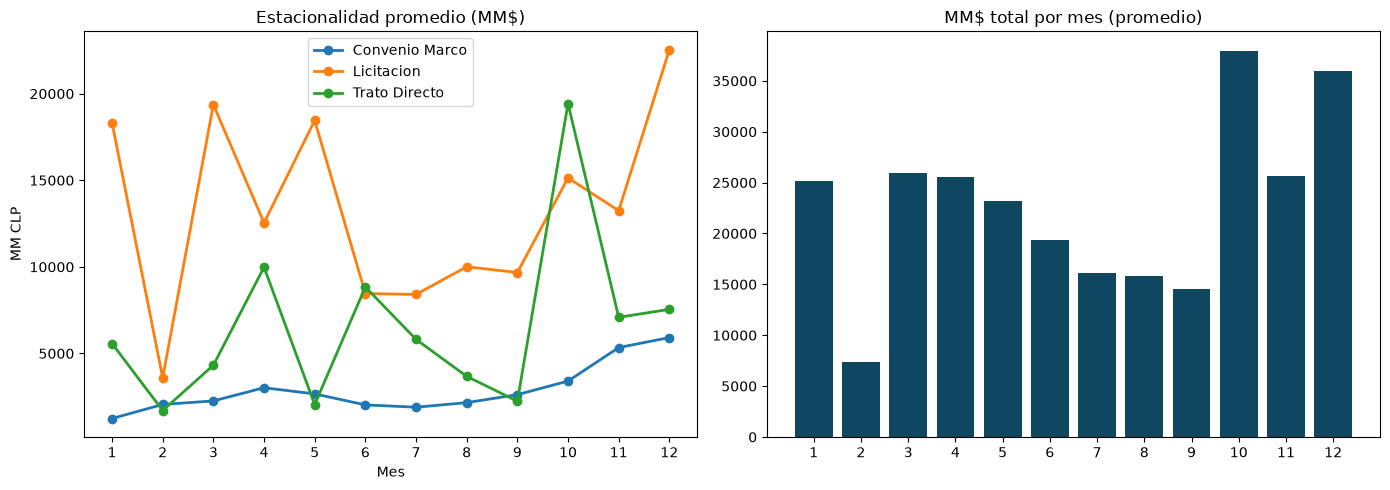

In [4]:
tabla_C = it.groupby(["Anio","Mes","TipoCompra"]).agg(
    N_OC=("codigoOC","nunique"), MM=("MM","sum")
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14,5))
for tipo, grp in tabla_C.groupby("TipoCompra"):
    pivot = grp.groupby("Mes").MM.sum() / 2
    axes[0].plot(pivot.index, pivot.values, marker="o", label=tipo, linewidth=2)
axes[0].set_title("Estacionalidad promedio (MM$)"); axes[0].set_xlabel("Mes")
axes[0].set_ylabel("MM CLP"); axes[0].legend(); axes[0].set_xticks(range(1,13))

total_mes = tabla_C.groupby("Mes").MM.sum() / 2
axes[1].bar(total_mes.index, total_mes.values, color="#0F4761")
axes[1].set_title("MM$ total por mes (promedio)"); axes[1].set_xticks(range(1,13))
plt.tight_layout()
plt.savefig("../05_figuras/nb03_fig1_estacionalidad.png", dpi=120, bbox_inches="tight")
plt.show()
tabla_C.to_csv("../05_figuras/tabla_C_estacionalidad.csv",sep=";",index=False,encoding="utf-8-sig")

## 3.4 Tabla D — Proyectos BIP × Compras

In [5]:
proy = (it.dropna(subset=["NombreProyecto"])
         .groupby(["CodBIP","Anio"], as_index=False)
         .agg(Gasto_Proy_MM  = ("Proy_Gasto_MM","first"),
              Compras_MM     = ("MM","sum"),
              N_OC           = ("codigoOC","nunique")))
proy = proy[(proy.Gasto_Proy_MM>0) & (proy.Compras_MM>0)].copy()
proy["Pct_Compras_vs_Gasto"] = 100 * proy["Compras_MM"] / proy["Gasto_Proy_MM"]

print(f"Tabla D: {len(proy):,} proyectos BIP con compras")
display(proy.sort_values("Compras_MM",ascending=False).head(10)
        .style.format({"Gasto_Proy_MM":"${:,.1f}","Compras_MM":"${:,.1f}","Pct_Compras_vs_Gasto":"{:.1f}%"})
        .set_caption("Tabla D. Proyectos BIP con mayor monto de compras"))
proy.to_csv("../05_figuras/tabla_D_proyectos_BIP.csv",sep=";",index=False,encoding="utf-8-sig")

Tabla D: 174 proyectos BIP con compras


,CodBIP,Anio,Gasto_Proy_MM,Compras_MM,N_OC,Pct_Compras_vs_Gasto
49,30224272.000000,2019,$872.1,"$4,990.6",2,572.3%
94,30481229.000000,2018,"$6,280.6","$3,966.6",720,63.2%
139,40002700.000000,2019,"$12,086.5","$3,772.0",650,31.2%
51,30224274.000000,2018,"$14,592.5","$3,414.5",3,23.4%
147,40002757.000000,2019,"$4,472.4","$3,390.5",840,75.8%
108,30481254.000000,2018,"$9,558.5","$2,560.7",216,26.8%
50,30224273.000000,2018,"$47,509.3","$1,920.1",45,4.0%
143,40002751.000000,2019,"$5,426.3","$1,379.8",377,25.4%
169,40010792.000000,2019,"$1,427.1","$1,151.6",39,80.7%
144,40002752.000000,2019,"$7,505.4",$975.9,239,13.0%


## 3.5 Tabla E — Trato Directo por Servicio (Riesgo)

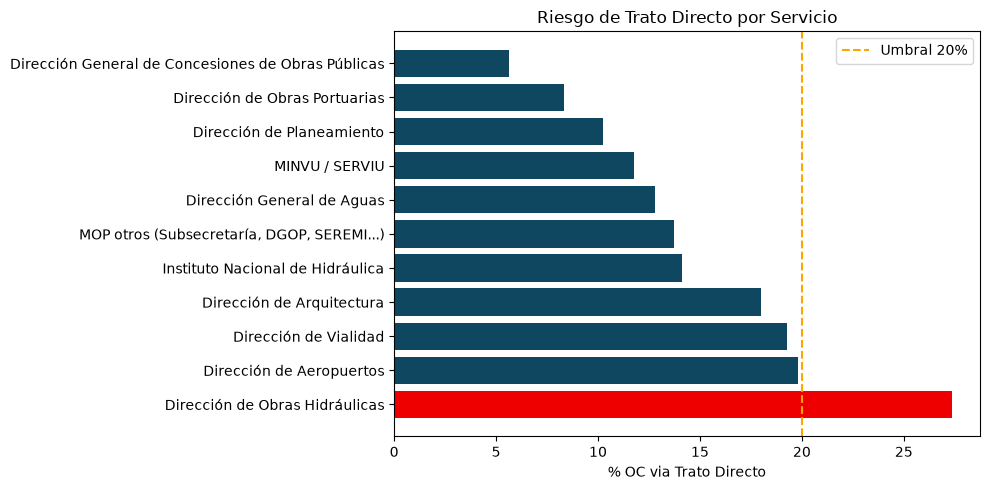

,Servicio,Pct_TD_OC,MM_Trato_Directo
4,Dirección de Obras Hidráulicas,27.4%,"$20,568.2"
2,Dirección de Aeropuertos,19.8%,$356.3
7,Dirección de Vialidad,19.3%,"$54,832.3"
3,Dirección de Arquitectura,18.0%,"$24,503.3"
8,Instituto Nacional de Hidráulica,14.1%,$109.5
10,"MOP otros (Subsecretaría, DGOP, SEREMI...)",13.7%,"$8,530.0"
0,Dirección General de Aguas,12.8%,$557.7
9,MINVU / SERVIU,11.7%,"$45,806.6"
6,Dirección de Planeamiento,10.2%,$138.9
5,Dirección de Obras Portuarias,8.3%,$672.8


In [6]:
oc_tipo = it.groupby(["codigoOC","Servicio","TipoCompra"]).MM.sum().reset_index()
td_pct  = (oc_tipo.groupby("Servicio")
            .apply(lambda d: 100*(d.TipoCompra=="Trato Directo").mean(), include_groups=False)
            .rename("Pct_TD_OC").reset_index())
td_mm   = (oc_tipo[oc_tipo.TipoCompra=="Trato Directo"]
            .groupby("Servicio").MM.sum().rename("MM_Trato_Directo").reset_index())
tabla_E = td_pct.merge(td_mm, on="Servicio", how="left").sort_values("Pct_TD_OC", ascending=False)

fig, ax = plt.subplots(figsize=(10,5))
colores = ["#EE0000" if p>20 else "#0F4761" for p in tabla_E.Pct_TD_OC]
ax.barh(tabla_E.Servicio, tabla_E.Pct_TD_OC, color=colores)
ax.axvline(20, color="orange", ls="--", label="Umbral 20%")
ax.set_xlabel("% OC via Trato Directo"); ax.set_title("Riesgo de Trato Directo por Servicio")
ax.legend(); plt.tight_layout()
plt.savefig("../05_figuras/nb03_fig2_trato_directo.png", dpi=120, bbox_inches="tight")
plt.show()
display(tabla_E.style.format({"Pct_TD_OC":"{:.1f}%","MM_Trato_Directo":"${:,.1f}"})
        .set_caption("Tabla E. Riesgo de Trato Directo por Servicio"))
tabla_E.to_csv("../05_figuras/tabla_E_trato_directo.csv",sep=";",index=False,encoding="utf-8-sig")